In [1]:
import pandas as pd

file_path = '/home/abhajkhan/Code/mca-tkmce/bipolar-disorder-severity-assessment-system/data/Bipolar_preprocessed.csv'
df = pd.read_csv(file_path)

display(df.head())

/usr/lib/python3/dist-packages/pytz/__init__.py:31: SyntaxWarning: invalid escape sequence '\s'
  match = re.match("^#\s*version\s*([0-9a-z]*)\s*$", line)


,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
0,0.532967,0.293343,0.010967,0.692430,0.041212,0.139536,0.374633,0.209127,0.054453,0.003024,...,False,False,False,False,False,False,True,False,False,False
1,0.767857,0.644235,0.005982,0.598200,0.012910,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,True,False,True,False,False,False,False,False
2,0.506868,0.346951,0.006979,0.583025,0.006951,0.031978,0.343365,0.033378,0.054453,0.002022,...,False,False,False,False,False,False,False,False,True,False
3,0.644231,0.507777,0.005982,0.584966,0.006951,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,False,True,False,False,False,False,False,False
4,0.520604,0.361572,0.010967,0.585848,0.015889,0.031978,0.437170,0.033378,0.054453,0.003024,...,False,False,False,False,True,False,False,False,False,False


In [2]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import numpy as np

# It's good practice to scale the data before DBSCAN, especially if features have different scales.
# However, given the context of 'Bipolar_preprocessed.csv', the data might already be scaled (e.g., between 0 and 1).
# If not, you might consider adding a StandardScaler step here.

X = df.copy()

# DBSCAN parameters: eps (maximum distance between two samples for one to be considered as in the neighborhood of the other),
# min_samples (the number of samples in a neighborhood for a point to be considered as a core point).
# These values are highly dependent on your dataset and often require experimentation.
# I'll start with some initial values. You might need to adjust them.
eps_value = 4.0 # Reverted to 3.0, which previously yielded 2 clusters
min_samples_value = 5 # Example value, adjust based on expected cluster size

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples_value)
clusters = dbscan.fit_predict(X)
df['DBSCAN_Cluster'] = clusters

print(f"DBSCAN found {len(np.unique(clusters)) - (1 if -1 in clusters else 0)} clusters (excluding noise).")
print(f"Number of noise points (label -1): {np.sum(clusters == -1)}")

DBSCAN found 5 clusters (excluding noise).
Number of noise points (label -1): 29


/tmp/ipykernel_68139/3391932713.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['DBSCAN_Cluster'] = clusters


Now, let's evaluate the clusters using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index. These metrics require at least two clusters and no noise points to be considered for evaluation.

In [3]:
# Filter out noise points (-1 label) for metric calculation
valid_indices = clusters != -1
filtered_X = X[valid_indices] # Use the original feature DataFrame X
filtered_clusters = clusters[valid_indices]


if len(np.unique(filtered_clusters)) < 2:
    print("Not enough clusters (excluding noise) to compute evaluation metrics (need at least 2). Adjust eps and min_samples.")
elif len(filtered_X) < 2:
    print("Not enough samples (excluding noise) to compute evaluation metrics.")
else:
    # Silhouette Score
    silhouette = silhouette_score(filtered_X, filtered_clusters)
    print(f"Silhouette Score: {silhouette:.3f}")

    # Davies-Bouldin Index
    davies_bouldin = davies_bouldin_score(filtered_X, filtered_clusters)
    print(f"Davies-Bouldin Index: {davies_bouldin:.3f}")

    # Calinski-Harabasz Index
    calinski_harabasz = calinski_harabasz_score(filtered_X, filtered_clusters)
    print(f"Calinski-Harabasz Index: {calinski_harabasz:.3f}")


Silhouette Score: 0.298
Davies-Bouldin Index: 1.310
Calinski-Harabasz Index: 100.748


Next, let's count the number of observations in each cluster, including noise points.

In [4]:
cluster_counts = pd.Series(clusters).value_counts().sort_index()
print("Count of observations in each cluster (including noise '-1'):")
display(cluster_counts)


Count of observations in each cluster (including noise '-1'):


-1     29
 0    155
 1     20
 2     75
 3     25
 4     38
Name: count, dtype: int64

### Assigning Noise Points to Clusters using K-Nearest Neighbors

In [5]:
from sklearn.neighbors import NearestNeighbors

# Create a copy of the clusters array to modify
new_clusters = clusters.copy()

# Separate noise points and clustered points
noise_indices = np.where(clusters == -1)[0]
clustered_indices = np.where(clusters != -1)[0]

# Only proceed if there are noise points to assign
if len(noise_indices) > 0 and len(clustered_indices) > 0:
    # Get the data for clustered points
    X_clustered = X.iloc[clustered_indices]
    y_clustered = clusters[clustered_indices]

    # Fit NearestNeighbors model on the clustered data
    # We'll look for the single nearest neighbor (k=1)
    nbrs = NearestNeighbors(n_neighbors=1, algorithm='auto').fit(X_clustered)

    # Find the nearest neighbor for each noise point among the clustered points
    # distances will be the distance to the nearest neighbor
    # indices will be the index in X_clustered of the nearest neighbor
    distances, indices = nbrs.kneighbors(X.iloc[noise_indices])

    # Assign each noise point to the cluster of its nearest clustered neighbor
    for i, noise_idx in enumerate(noise_indices):
        # Get the original index of the nearest clustered point
        nearest_clustered_original_idx = clustered_indices[indices[i][0]]
        # Assign the cluster label of the nearest clustered point to the noise point
        new_clusters[noise_idx] = clusters[nearest_clustered_original_idx]

    print("Noise points have been assigned to the nearest clusters.")
elif len(noise_indices) == 0:
    print("No noise points (label -1) were found by DBSCAN, so no assignment is needed.")
else:
    print("Not enough clustered points to assign noise points.")

# Update the 'DBSCAN_Cluster' column in the DataFrame with the new clusters
df['DBSCAN_Cluster_with_noise_assigned'] = new_clusters

print("Updated cluster counts:")
display(pd.Series(new_clusters).value_counts().sort_index())

Noise points have been assigned to the nearest clusters.
Updated cluster counts:


/tmp/ipykernel_68139/371903421.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['DBSCAN_Cluster_with_noise_assigned'] = new_clusters


0    170
1     26
2     77
3     27
4     42
Name: count, dtype: int64

### Visualizing Feature Distributions for Cluster 0 vs Cluster 1 (with noise points assigned)

In [6]:
# Recalculate differentiating features using the new cluster assignments

# Ensure the 'DBSCAN_Cluster_with_noise_assigned' column exists
if 'DBSCAN_Cluster_with_noise_assigned' not in df.columns:
    print("Error: 'DBSCAN_Cluster_with_noise_assigned' column not found. Please run the previous cell to assign noise points.")
else:
    # Get the data for the two main clusters (0 and 1)
    clusters_for_diff = df['DBSCAN_Cluster_with_noise_assigned'].unique()
    clusters_for_diff = [c for c in clusters_for_diff if c != -1] # Ensure we only consider actual clusters

    if len(clusters_for_diff) >= 2:
        cluster_means_assigned = df.groupby('DBSCAN_Cluster_with_noise_assigned').mean(numeric_only=True)

        # Exclude the 'DBSCAN_Cluster' column itself from the mean calculation if it exists in the original df
        # (It shouldn't be there if X was used for clustering, but for safety)
        if 'DBSCAN_Cluster' in cluster_means_assigned.columns:
            cluster_means_assigned = cluster_means_assigned.drop(columns=['DBSCAN_Cluster'])

        # Calculate overall means for the full dataset now that all points are assigned
        overall_means_assigned = df.drop(columns=['DBSCAN_Cluster', 'DBSCAN_Cluster_with_noise_assigned'], errors='ignore').mean(numeric_only=True)

        # Calculate absolute difference from overall mean for each cluster, then average these differences
        feature_diff_assigned = cluster_means_assigned.subtract(overall_means_assigned, axis=1).abs().mean(axis=0)

        print("Top 10 most differentiating features (based on absolute mean difference from overall mean across newly assigned clusters):")
        top_10_features = feature_diff_assigned.nlargest(10).index.tolist()
        display(feature_diff_assigned.nlargest(10))
    else:
        print("Not enough clusters (after noise assignment) to calculate differentiating features.")

Top 10 most differentiating features (based on absolute mean difference from overall mean across newly assigned clusters):


del_ctrl_Unknown            0.544444
del_soma_Unknown            0.544444
thought_phen_Unknown        0.544444
ah_Unknown                  0.544444
vh_Unknown                  0.544444
disorg_speech_Unknown       0.544444
catatonia_Unknown           0.544444
del_sin_Unknown             0.540267
disorg_behaviour_Unknown    0.540267
del_ref_Unknown             0.529268
dtype: float64

Figures will be saved to: /home/abhajkhan/Code/mca-tkmce/bipolar-disorder-severity-assessment-system/notebooks/ppt_outputs/dbscan


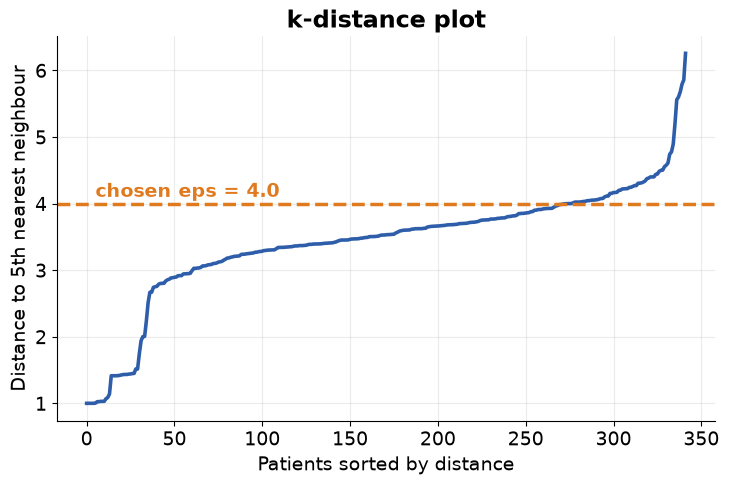

saved -> ppt_outputs/dbscan/01_k_distance.png


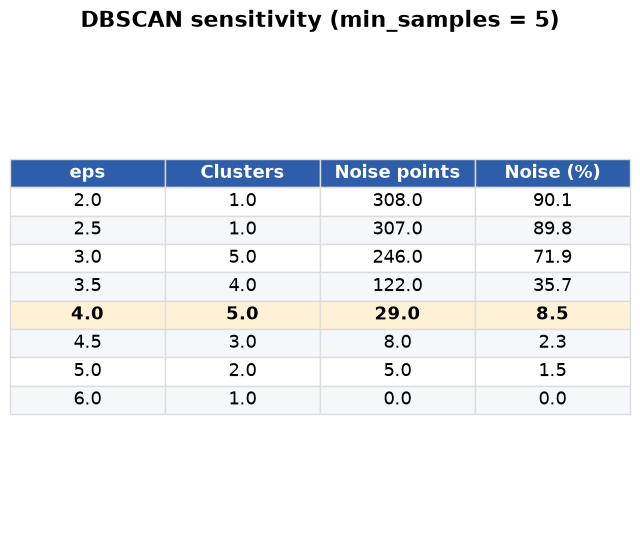

saved -> ppt_outputs/dbscan/02_eps_sensitivity.png


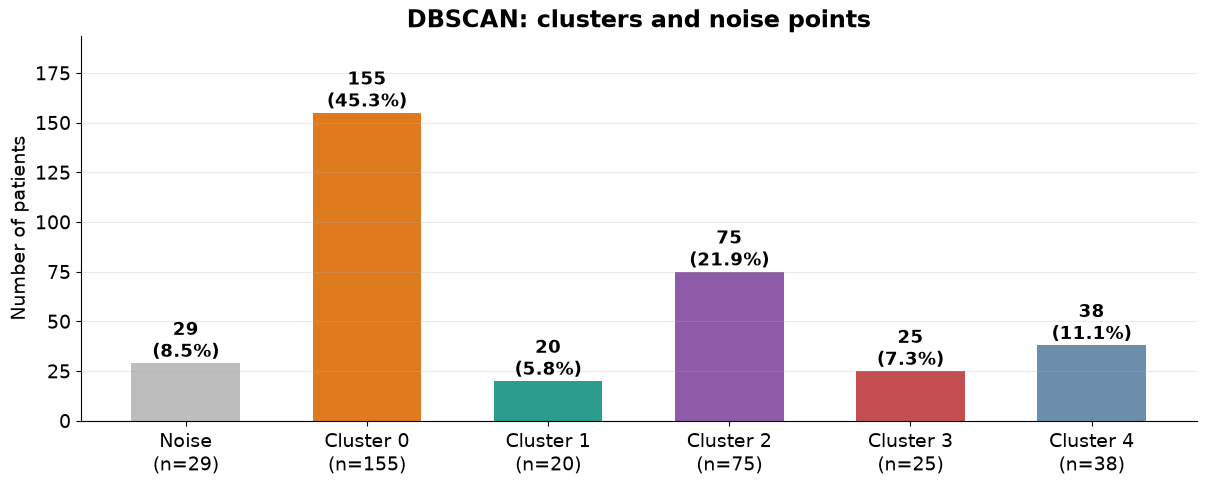

saved -> ppt_outputs/dbscan/03_sizes_with_noise.png


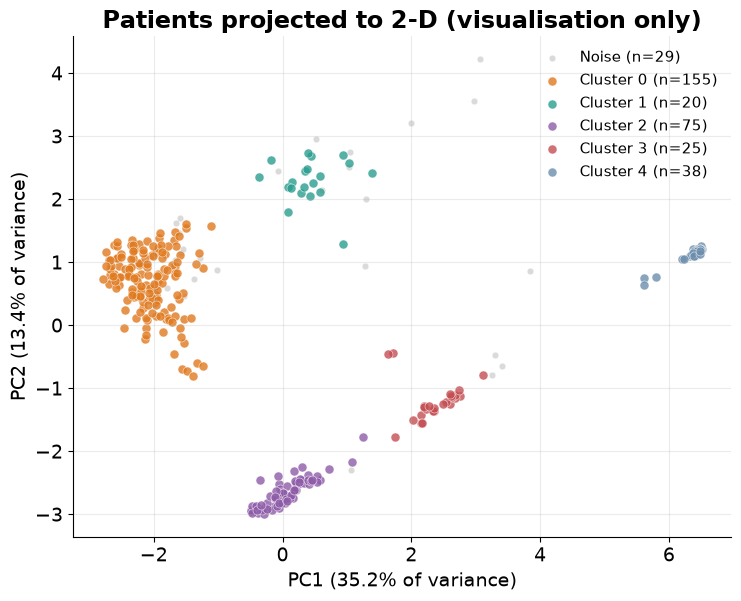

saved -> ppt_outputs/dbscan/04_pca_scatter.png


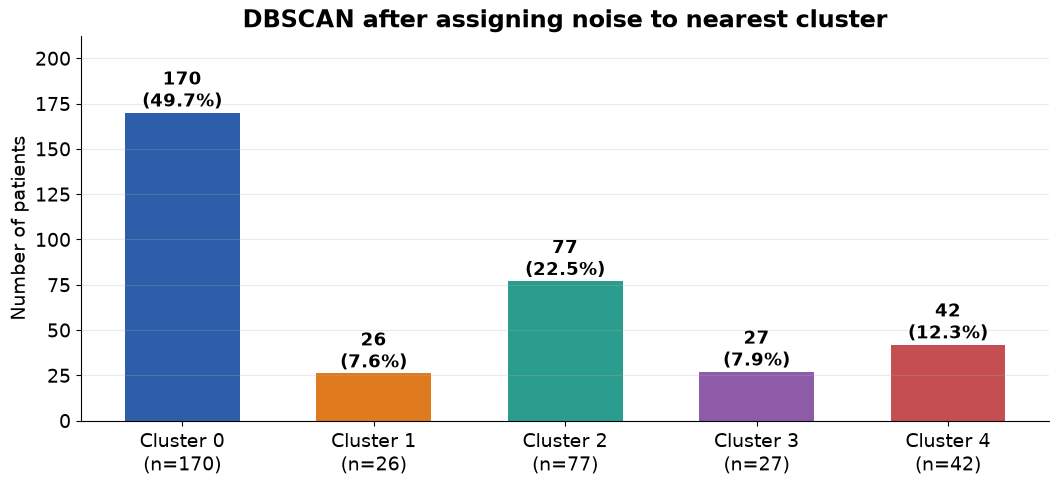

saved -> ppt_outputs/dbscan/05_sizes_noise_assigned.png


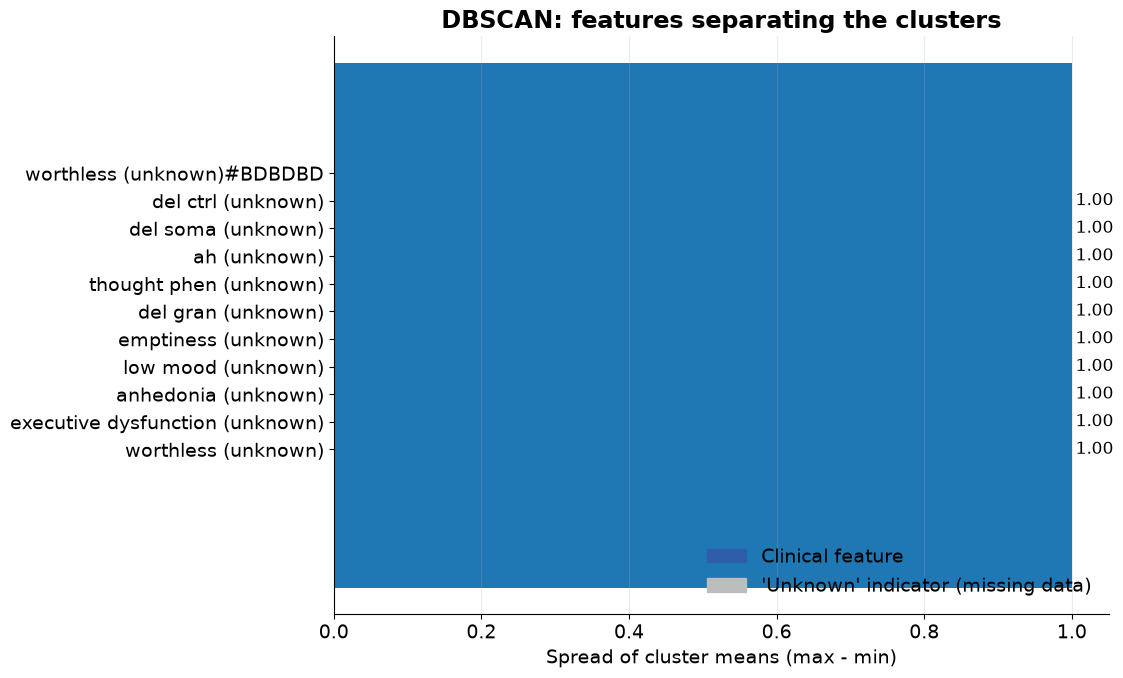

saved -> ppt_outputs/dbscan/06_top_features.png


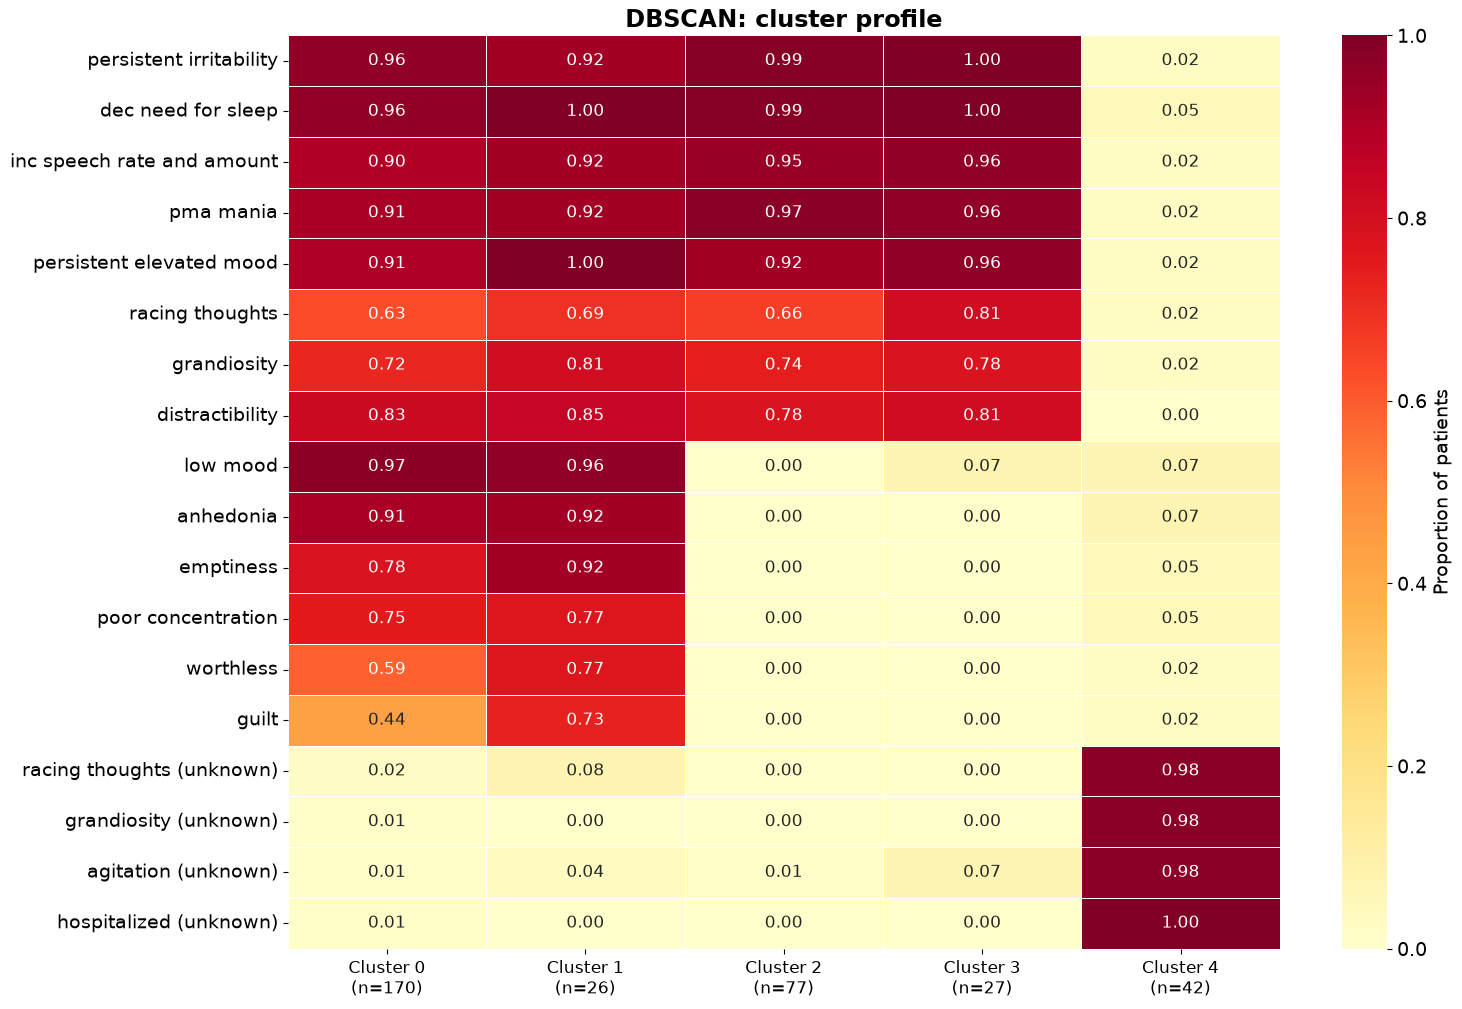

saved -> ppt_outputs/dbscan/07_profile_heatmap.png


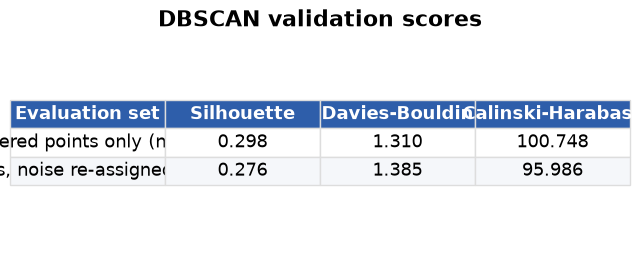

saved -> ppt_outputs/dbscan/08_metrics.png


In [7]:
# ===== Append to the END of BD_DBSCAN notebook =====
# %% CELL 1 - setup + k-distance plot (justifies eps)
from ppt_helpers import *
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
setup("dbscan")

X = feature_matrix(df)
EPS, MIN_S = 4.0, 5
d, _ = NearestNeighbors(n_neighbors=MIN_S).fit(X).kneighbors(X)
kd = np.sort(d[:, -1])
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(kd, lw=2.6, color=COLORS[0])
ax.axhline(EPS, color=HILITE, ls="--", lw=2.5)
ax.text(5, EPS + .1, f"chosen eps = {EPS}", color=HILITE, fontsize=14, weight="bold")
ax.set_xlabel("Patients sorted by distance"); ax.set_ylabel(f"Distance to {MIN_S}th nearest neighbour")
ax.set_title("k-distance plot")
save("01_k_distance")

# %% CELL 2 - eps sensitivity table
rows = []
for eps in [2, 2.5, 3, 3.5, 4, 4.5, 5, 6]:
    l = DBSCAN(eps=eps, min_samples=MIN_S).fit_predict(X)
    rows.append({"eps": eps, "Clusters": len(set(l)) - (1 if -1 in l else 0),
                 "Noise points": int((l == -1).sum()), "Noise (%)": round((l == -1).mean() * 100, 1)})
sens = pd.DataFrame(rows)
table_png(sens, "02_eps_sensitivity", title=f"DBSCAN sensitivity (min_samples = {MIN_S})",
          highlight_rows=[list(sens.eps).index(EPS)], digits=1)

# %% CELL 3 - final DBSCAN result incl. noise
raw = DBSCAN(eps=EPS, min_samples=MIN_S).fit_predict(X)
size_bar(raw, "03_sizes_with_noise", None, "DBSCAN: clusters and noise points")
pca_scatter(X, raw, "04_pca_scatter", None)

# %% CELL 4 - noise re-assigned to nearest cluster (as in the notebook)
core = raw != -1
nn = NearestNeighbors(n_neighbors=1).fit(X.values[core])
_, idx = nn.kneighbors(X.values[~core])
assigned = raw.copy()
assigned[~core] = raw[core][idx[:, 0]]
size_bar(assigned, "05_sizes_noise_assigned", None, "DBSCAN after assigning noise to nearest cluster")

# %% CELL 5 - what drives DBSCAN clusters? (shows the 'Unknown' issue)
diff_features_bar(X, assigned, "06_top_features", top=10,
                  title="DBSCAN: features separating the clusters")
profile_heatmap(X, assigned, "07_profile_heatmap", None, title="DBSCAN: cluster profile")

# %% CELL 6 - metrics table (two views)
def m(Xv, l):
    return [silhouette_score(Xv, l), davies_bouldin_score(Xv, l), calinski_harabasz_score(Xv, l)]
a = m(X.values[core], raw[core])
b = m(X.values, assigned)
mt = pd.DataFrame({"Evaluation set": [f"Clustered points only (n={core.sum()})",
                                      f"All points, noise re-assigned (n={len(X)})"],
                   "Silhouette": [a[0], b[0]], "Davies-Bouldin": [a[1], b[1]],
                   "Calinski-Harabasz": [a[2], b[2]]})
table_png(mt, "08_metrics", title="DBSCAN validation scores")
